# 👋 Lesson 00 · Welcome, Setup & Your First Neural Network

*“The best way to understand a neural network is to watch one learn: then build one yourself.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~60 min | 🟢 Beginner | Day 1 | Basic Python, a little NumPy |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Explain, in plain words, what deep learning is and when it is the right tool
- Verify that your computer is ready (Python, NumPy, PyTorch, datasets)
- Train your very first neural network on real handwritten digits
- Navigate the course: lessons → problems → hints → solutions → projects
- Refresh the NumPy skills (shapes, broadcasting, vectorisation) that every later lesson relies on

## 🗺 Roadmap
1. Welcome & how this course works
2. Course map
3. Environment check
4. Demo: a neural network in 25 lines
5. Tour of our four datasets
6. What *is* deep learning?
7. NumPy warm-up
8. Practice problems

---
## 👋 1. Welcome!

Hello, and welcome; I'm really glad you're here.

Over the next **two weeks** you will travel from *"neural networks sound like magic"* to
*"I trained one, I understand **why** it works, and I can tell when it is lying to me."*

I'm going to teach this the way I'd want to be taught:

* **Intuition first, then maths, then code.** Every idea gets a story or a picture *before* it gets an equation.
* **We build it from scratch before we use the library.** You'll write a neuron, a network and backpropagation
  in plain NumPy. Only then do we let PyTorch do the heavy lifting, and it will feel like a favour, not a mystery.
* **Real data, real problems.** Handwritten digits, clothing photos, **maize-leaf diseases** and **maize market prices**
: problems that matter for agriculture, where deep learning can genuinely help farmers.
* **Mistakes are the curriculum.** I will deliberately show you things that break. Bugs are where understanding lives.

> 🧭 **The one rule:** *type the code yourself and change it.* Copy-pasting teaches your clipboard, not you.
> After each cell, ask: *"What if I changed this number?"*: then change it and find out.

### 🔁 The learning loop we'll follow in every lesson

| Step | What you do | Why |
|:--|:--|:--|
| 1. **Read** | Skim the objectives and roadmap | Your brain learns better when it knows where it's going |
| 2. **Run** | Execute each cell, top to bottom | See the idea work |
| 3. **Break** | Change numbers, delete lines, predict what happens | Turns watching into understanding |
| 4. **Practise** | Do the 🏋️ problems at the bottom (hints are collapsible!) | Retrieval practice is the strongest learning tool we know |
| 5. **Explain** | Teach the key takeaways to a friend (or a rubber duck 🦆) | If you can't explain it simply, find the gap |
| 6. **Build** | Use it in a project | Knowledge becomes skill |

**How to use hints.** Struggle for ~10 minutes first. Then open Hint 1. Then wait 5 more minutes. Only after Hint 3
(or solid effort) look at the solution in `../solutions/`. *Productive struggle* is not wasted time: it's the workout.

---
## 🗺 2. The course map

This course covers **Phase 8: Deep Learning & Neural Networks** (Weeks 16–17). Here is how every topic on your
syllabus maps to a lesson:

| # | Lesson | Phase-8 topics covered | Project |
|:-:|:--|:--|:--|
| 00 | Welcome & setup | Course orientation, NumPy refresh | First network demo |
| 01 | The artificial neuron & perceptron | Artificial neurons · perceptrons · weights & biases | |
| 02 | Layers & activation functions | Input/hidden/output layers · activation functions | |
| 03 | Forward propagation & loss functions | Forward propagation · loss functions | |
| 04 | Gradient descent & backpropagation | Backpropagation · gradient descent · learning rate | |
| 05 | PyTorch fundamentals | Frameworks (PyTorch), ANN in practice | |
| 06 | Optimizers, learning rates, epochs & batches | Optimizers · learning rates · epochs · batch sizes | |
| 07 | **Project 1**: Handwritten digits | ANN | ✍️ MNIST |
| 08 | Convolutional neural networks | CNN | |
| 09 | **Project 2**: Image classification | CNN, evaluation | 👕 Fashion-MNIST |
| 10 | **Project 3**: Crop disease classification | CNN, augmentation, deployment thinking | 🌽 Maize leaves |
| 11 | RNNs, LSTMs & GRUs | RNN · LSTM · GRU | |
| 12 | **Project 4**: Price forecasting with LSTM | LSTM for agriculture | 📈 Maize prices |
| 13 | Transformers | Attention · Transformers | Mini Vision Transformer |
| 14 | Optimisation & regularisation | Dropout · batch-norm · early stopping · regularisation · LR scheduling | |
| 15 | Keras & TensorFlow bridge | TensorFlow · Keras familiarity | |
| 16 | 🏆 **Capstone**: *FieldAdvisor* | Everything | Leaf-disease + price advisor |

*Suggested pacing is in `SYLLABUS.md` (10 study days). Prefer a slower pace? Do one lesson per day, and treat the projects as weekend work.*

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl

dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 🔧 3. Is your environment ready?

Let's check Python, the libraries, and whether you have a GPU. **A GPU is *not* required**: every notebook in this course is designed to run on an ordinary laptop CPU.

In [2]:
import sys, platform
import torch, sklearn, pandas as pd
print("Python      :", sys.version.split()[0], f"({platform.system()})")
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("PyTorch     :", torch.__version__)
print("Device      :", dl.get_device(), "← 'cpu' is perfectly fine for this course")

Python      : 3.12.3 (Linux)
NumPy       : 2.5.4
Pandas      : 3.0.6
scikit-learn: 1.9.1
PyTorch     : 2.15.0+cu132
Device      : cpu ← 'cpu' is perfectly fine for this course


Now let's make sure all four datasets load. If this cell fails, check that you unzipped the **whole** course folder (the `data/` directory must sit next to `notebooks/`).

In [3]:
xtr, ytr, xte, yte = dl.load_mnist()
print("MNIST   :", xtr.shape, xte.shape, "→ handwritten digits 0-9")
xtr_f, ytr_f, xte_f, yte_f = dl.load_fashion()
print("Fashion :", xtr_f.shape, xte_f.shape, "→ 10 clothing categories")
leaves = dl.load_leaves()
print("Leaves  :", leaves["x_train"].shape, "→ 5 maize leaf conditions (RGB 48×48)")
prices = dl.load_prices()
print("Prices  :", prices.shape, "→ weekly Nairobi maize prices", prices.date.min().date(), "to", prices.date.max().date())

MNIST   : (20000, 28, 28) (5000, 28, 28) → handwritten digits 0-9


Fashion : (15000, 28, 28) (5000, 28, 28) → 10 clothing categories


Leaves  : (2100, 48, 48, 3) → 5 maize leaf conditions (RGB 48×48)
Prices  : (783, 4) → weekly Nairobi maize prices 2011-01-03 to 2025-12-29


> ⚠️ **Watch out**: If `import torch` fails, install it with `pip install torch` (see `README.md` for the CPU-only command, which is a much smaller download). Then restart the kernel.

---
## 🚀 4. Demo: your first neural network in ~25 lines

Before we learn *anything*, let's see the magic trick. We'll teach a small neural network to read handwritten digits.
**You are not expected to understand every line yet**: by Lesson 05 you will be able to write this from memory.
Just watch what happens to the accuracy as the network learns.

In [4]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. DATA: 5,000 handwritten digits (each 28×28 pixels, flattened to 784 numbers)
x_train, y_train, x_test, y_test = dl.load_mnist(n_train=5000, n_test=2000, flatten=True)
train_dl = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train)), batch_size=64, shuffle=True)
test_dl  = DataLoader(TensorDataset(torch.tensor(x_test),  torch.tensor(y_test)),  batch_size=256)

# 2. MODEL: 784 pixels → 64 hidden neurons → 10 outputs (one per digit)
model = nn.Sequential(nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, 10))

# 3. LOSS + OPTIMISER: "how wrong are we?" and "how do we improve?"
loss_fn   = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 4. LEARN!  (dl.fit is the training loop you'll write yourself in Lesson 05)
history = dl.fit(model, train_dl, test_dl, loss_fn, optimizer, epochs=6, device=torch.device("cpu"))

epoch   1/6 | train loss 1.3051 | val loss 0.6020 | train acc 0.690 | val acc 0.870
epoch   2/6 | train loss 0.5127 | val loss 0.3775 | train acc 0.873 | val acc 0.906


epoch   3/6 | train loss 0.3778 | val loss 0.3151 | train acc 0.905 | val acc 0.918
epoch   4/6 | train loss 0.3141 | val loss 0.2857 | train acc 0.919 | val acc 0.918


epoch   5/6 | train loss 0.2764 | val loss 0.2698 | train acc 0.924 | val acc 0.924
epoch   6/6 | train loss 0.2461 | val loss 0.2525 | train acc 0.933 | val acc 0.932
done in 2.3s


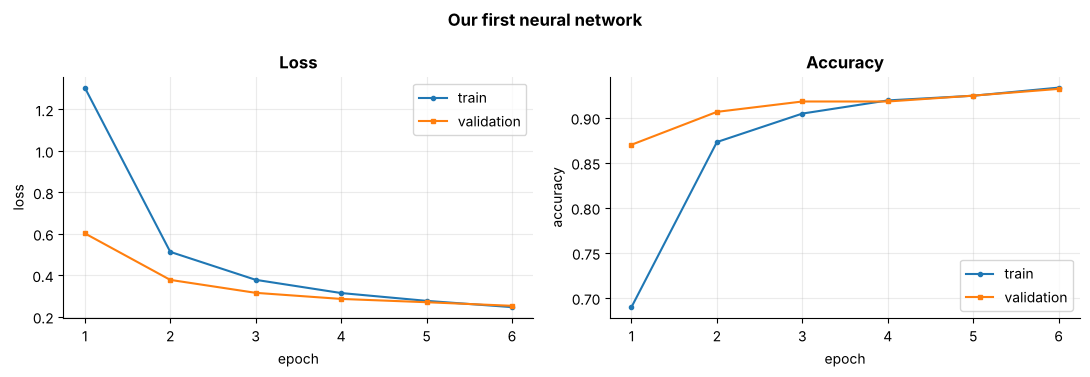

In [5]:
dl.plot_history(history, 'Our first neural network')

**What just happened?** The network started out guessing at random (~10 % accuracy: one in ten digits).
After a handful of passes over the data it reads ~90 %+ of *unseen* digits correctly. Nobody told it what a "7" looks like.
It *discovered* useful patterns by repeatedly (a) guessing, (b) measuring how wrong it was, and (c) nudging its internal
numbers to be slightly less wrong. **That loop is deep learning.** The rest of the course is about understanding each part of it.

Let's look at some of its predictions: green means correct, red means wrong:

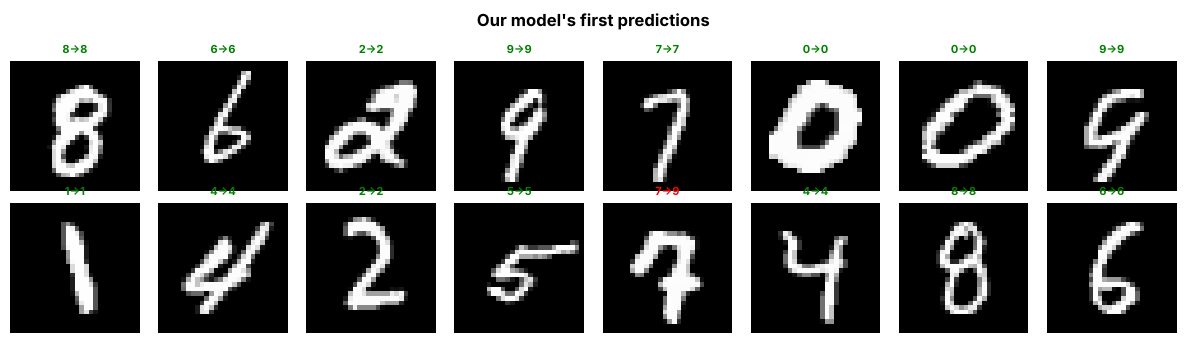

In [6]:
import torch
with torch.no_grad():
    preds = model(torch.tensor(x_test[:16])).argmax(1).numpy()
dl.show_images(x_test[:16].reshape(-1, 28, 28), y_test[:16], preds=preds, n=16, ncols=8, title="Our model's first predictions")

---
## 🔭 5. Tour of our four datasets

A good engineer *looks at the data first.* Here are the four datasets that power the projects.

| Dataset | What it is | Real or synthetic? | Used in |
|:--|:--|:--|:--|
| **MNIST** | 70k handwritten digits (we ship a 25k subset) | ✅ Real | Lessons 4–9, 13–14 |
| **Fashion-MNIST** | Zalando clothing images, 10 classes | ✅ Real | Lesson 9 |
| **Maize leaves** | 3,000 small RGB leaf photos, 5 conditions | 🧪 Synthetic (generated, see `data/build_datasets.py`) | Lessons 10, 16 |
| **Maize prices** | 15 years of weekly prices, 3 Kenyan markets | 🧪 Synthetic (seasonality + rainfall + fuel + droughts) | Lessons 12, 16 |

> 🧪 **Why synthetic for agriculture?** Real crop photos and price feeds are huge or require API keys, and we want
> this course to work offline and instantly. Synthetic data also lets us *know the ground truth*. The workflow you learn
> transfers directly to real data; Lesson 10 and the capstone show exactly how to swap it in (e.g. PlantVillage, KAMIS).

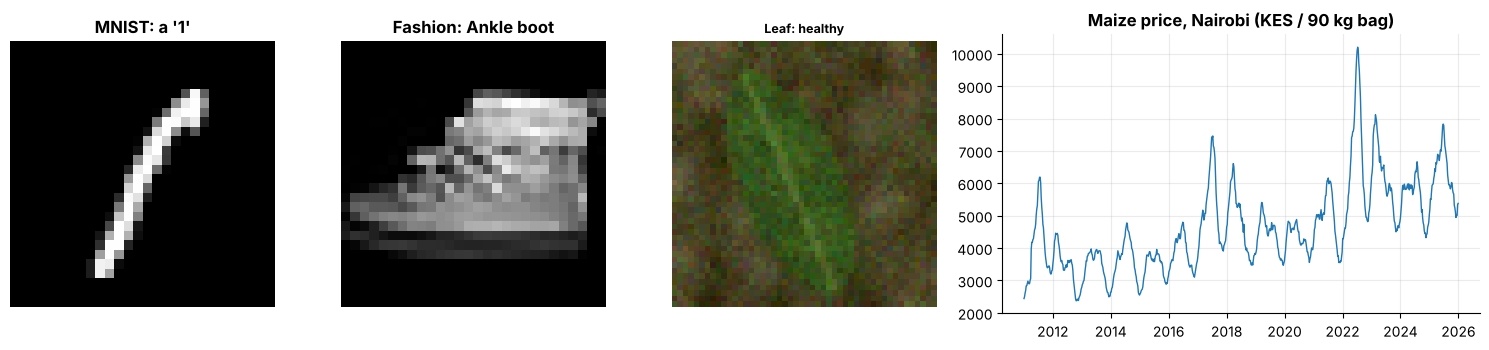

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.8]})
axes[0].imshow(xtr[0], cmap="gray"); axes[0].set_title(f"MNIST: a '{ytr[0]}'"); axes[0].axis("off")
axes[1].imshow(xtr_f[1], cmap="gray"); axes[1].set_title(f"Fashion: {dl.FASHION_CLASSES[ytr_f[1]]}"); axes[1].axis("off")
axes[2].imshow(leaves["x_train"][3]); axes[2].set_title(f"Leaf: {dl.LEAF_CLASSES[leaves['y_train'][3]]}", fontsize=9); axes[2].axis("off")
axes[3].plot(prices.date, prices.price_kes_90kg, lw=1); axes[3].set_title("Maize price, Nairobi (KES / 90 kg bag)")
plt.tight_layout(); plt.show()

🤔 **Pause and think.** Looking at the price chart: if you wanted to predict *next month's* price, what clues would you use?

<details><summary>Click to reveal the answer</summary>

Several! **Trend** (prices drift upward with inflation), **seasonality** (low after harvest, high in the lean months), **recent history** (prices are sticky: this week ≈ last week), and **outside drivers** like rainfall and fuel cost. In Lesson 12 you'll give an LSTM all of these clues and see which ones help.

</details>

---
## 🧠 6. So… what *is* deep learning?

Think of a **radio with 100,000 tiny dials**. Tuned correctly, it plays music; tuned badly, you hear static.
No human could set 100,000 dials by hand, so we build a machine that *listens to the static, then nudges every dial
a tiny bit in the direction that makes the sound clearer*, thousands of times. That is training a neural network:

* the **dials** are *weights and biases* (the *parameters*),
* the **"how bad is the static?"** meter is the *loss function*,
* the **"nudge each dial"** rule is *gradient descent* (using *backpropagation* to know which way to nudge),
* the **radio's wiring** is the *architecture* (ANN, CNN, RNN, Transformer…).

### Machine learning vs deep learning

| | Classical ML (e.g. random forest) | Deep learning |
|:--|:--|:--|
| Input | Hand-crafted features (you decide: "lesion area", "mean redness") | Raw data (pixels, text, time-series): the network learns its own features |
| Data needed | Hundreds – thousands of rows | Thousands – millions (less with transfer learning) |
| Best at | Tabular/spreadsheet data | Images, audio, text, sequences |
| Interpretability | Often easier | Harder (but we'll peek inside!) |
| Compute | Light | Heavier |

> 💡 **Big idea; Deep learning = learning *representations*.** Instead of an expert saying "look for brown rectangles
> on the leaf", the network *discovers* that brown rectangles are informative. "Deep" just means many layers of
> such discoveries, each built on the one before.

> ⚠️ **Honest advice from your professor:** deep learning is *not* always the answer. For a spreadsheet of 500 farms,
> gradient-boosted trees will often win. Part of becoming good is knowing when **not** to use a neural network.

---
## 🐍 7. NumPy warm-up (your daily bread)

Neural networks are **matrix arithmetic with a learning rule**. If you're fluent in three NumPy ideas, everything in this
course will feel natural:

1. **Shapes**: `(batch, features)`; always know your shapes.
2. **Broadcasting**: NumPy stretches small arrays to match big ones.
3. **Vectorisation**: one matrix multiply instead of a Python `for` loop (100× faster).

In [8]:
# A mini-batch of 4 farms, each described by 3 numbers: [rainfall_mm, soil_moisture, seed_price]
X = np.array([[120., 0.30, 55.],
              [ 80., 0.20, 60.],
              [200., 0.55, 52.],
              [ 40., 0.10, 70.]])
print("X shape:", X.shape, "  ← (batch=4, features=3)")

# Broadcasting: subtract each COLUMN's mean (shape (3,) is stretched across the 4 rows)
centered = X - X.mean(axis=0)
print("column means after centering:", centered.mean(axis=0).round(6))

# Vectorisation: a "neuron" for every farm at once → z = X @ w + b
w = np.array([0.02, 3.0, -0.05])
b = -1.0
z = X @ w + b
print("weighted sums z:", z.round(3), " shape:", z.shape)

X shape: (4, 3)   ← (batch=4, features=3)
column means after centering: [ 0. -0.  0.]
weighted sums z: [-0.45 -1.8   2.05 -3.4 ]  shape: (4,)


> ⚠️ **Watch out**: The #1 source of bugs in deep learning is **shape mismatch**. Make `print(x.shape)` your reflex. When you see `(4,)` vs `(4, 1)`: those are *different things* and will broadcast in surprising ways!

In [9]:
a = np.array([1., 2., 3., 4.])          # shape (4,)
col = a.reshape(-1, 1)                   # shape (4, 1)
print("(4,)  - (4,)  :", (a - a).shape)
print("(4,1) - (4,)  :", (col - a).shape, "← surprise: a 4×4 matrix! (every pair)")

(4,)  - (4,)  : (4,)
(4,1) - (4,)  : (4, 4) ← surprise: a 4×4 matrix! (every pair)


---
# 🏋️ Practice problems
These warm-ups diagnose your NumPy fitness. Don't worry if they feel slow: they're the *only* prerequisites. Hints are there for you.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 0.1: Standardise the columns  &nbsp; `⭐`

Write `standardize(X)` that subtracts each column's mean and divides by its standard deviation
(so every column has mean 0 and std 1). **No loops.**  We do this to almost every dataset before training.

<details><summary>💡 Hint 1</summary>

Which axis do you average over to get one number *per column*?

</details>

<details><summary>💡 Hint 2</summary>

`X.mean(axis=0)` has shape `(features,)`; broadcasting does the rest.

</details>

<details><summary>💡 Hint 3</summary>

Watch out for columns whose std is 0 → add a tiny `1e-8` to the denominator.

</details>


In [ ]:
def standardize(X):
    # YOUR CODE HERE
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
X = np.random.default_rng(0).normal(50, 10, size=(100, 3)) * [1, 5, 0.1]
Z = standardize(X)
dl.check("means ≈ 0", np.allclose(Z.mean(0), 0, atol=1e-6))
dl.check("stds ≈ 1", np.allclose(Z.std(0), 1, atol=1e-3))
dl.check("shape preserved", Z.shape == X.shape)

---
### 🧩 Problem 0.2: A whole layer in one line  &nbsp; `⭐⭐`

A layer with `n_out` neurons computes `Z = X @ W + b` where `X` is `(batch, n_in)`, `W` is `(n_in, n_out)`,
and `b` is `(n_out,)`. Write `dense(X, W, b)` returning `Z`, **and** the function `relu(Z)` that
replaces negative numbers with 0 (use `np.maximum`).
Then compute the output of `relu(dense(X, W, b))` for the provided data.

<details><summary>💡 Hint 1</summary>

Matrix multiply is `@` (or `np.dot`).

</details>

<details><summary>💡 Hint 2</summary>

`b` has shape `(n_out,)`: broadcasting adds it to every row for free.

</details>

<details><summary>💡 Hint 3</summary>

`np.maximum(0, Z)` works element-wise.

</details>


In [ ]:
def dense(X, W, b):
    pass          # YOUR CODE HERE

def relu(Z):
    pass          # YOUR CODE HERE

rng = np.random.default_rng(1)
X = rng.normal(size=(5, 4)); W = rng.normal(size=(4, 3)); b = rng.normal(size=3)
out = relu(dense(X, W, b))

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("output shape is (5, 3)", out is not None and out.shape == (5, 3))
dl.check("no negative values", out is not None and (out >= 0).all())
dl.check("matches manual first neuron", out is not None and np.isclose(out[0, 0], max(0, X[0] @ W[:, 0] + b[0])))

---
### 🧩 Problem 0.3: One-hot encoding  &nbsp; `⭐⭐`

Classifiers often need labels as **one-hot** vectors: class `3` out of 5 classes becomes `[0,0,0,1,0]`.
Write `one_hot(labels, num_classes)` that returns an array of shape `(len(labels), num_classes)`: **without a Python loop over the labels**.

<details><summary>💡 Hint 1</summary>

Start with `np.zeros((n, num_classes))`.

</details>

<details><summary>💡 Hint 2</summary>

Fancy indexing: `A[np.arange(n), labels] = 1` sets one entry per row.

</details>


In [ ]:
def one_hot(labels, num_classes):
    pass          # YOUR CODE HERE

In [ ]:
# ▶ self-check (run after you've written your answer)
oh = one_hot(np.array([3, 0, 4]), 5)
dl.check("shape (3,5)", oh is not None and oh.shape == (3, 5))
dl.check("row 0 is class 3", oh is not None and oh[0].argmax() == 3 and oh[0].sum() == 1)
dl.check("equals identity rows", oh is not None and np.array_equal(oh, np.eye(5)[[3, 0, 4]]))

---
### 🧩 Problem 0.4: Predict the broadcast (shape reasoning)  &nbsp; `⭐`

Without running anything, decide the resulting shape of each expression, then fill the dictionary `answers`
with tuples. (Then run the check, and *also* run the expressions to confirm!)

* `a`: `np.ones((8, 1)) + np.ones((1, 5))`
* `b`: `np.ones((8, 5)) * np.ones(5)`
* `c`: `np.ones((8, 5)).sum(axis=1)`
* `d`: `np.ones((8, 5)).sum(axis=1, keepdims=True)`

<details><summary>💡 Hint 1</summary>

Broadcasting aligns shapes from the *right*; a size-1 axis is stretched.

</details>

<details><summary>💡 Hint 2</summary>

`sum(axis=1)` removes axis 1; `keepdims=True` keeps it as size 1.

</details>


In [ ]:
answers = {"a": None, "b": None, "c": None, "d": None}   # e.g. {"a": (3, 3), ...}

In [ ]:
# ▶ self-check (run after you've written your answer)
truth = {"a": (np.ones((8,1)) + np.ones((1,5))).shape, "b": (np.ones((8,5)) * np.ones(5)).shape,
         "c": np.ones((8,5)).sum(axis=1).shape, "d": np.ones((8,5)).sum(axis=1, keepdims=True).shape}
for k in truth:
    dl.check(f"shape of {k}", answers.get(k) == truth[k])

---
## 🏁 Key takeaways
- ✅ Deep learning = a flexible function with many adjustable numbers (**parameters**) that we tune by **measure error → nudge → repeat**.
- ✅ Training has four ingredients: **data, model (architecture), loss function, optimiser**.
- ✅ Neural-network maths is mostly **matrix multiplication + a non-linearity**: NumPy fluency pays off every day.
- ✅ Always know your **shapes**. When in doubt, `print(x.shape)`.
- ✅ Deep learning is powerful for images, text and sequences, but not a universal hammer.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** In one sentence, what does *training* a neural network mean?

<details><summary>Answer</summary>

Repeatedly measuring how wrong the network's predictions are (the **loss**) and adjusting its **weights and biases** a little in the direction that reduces that loss.

</details>

**Q2.** Why did we put `dl.set_seed(42)` at the top of the notebook?

<details><summary>Answer</summary>

Neural networks start from random weights and shuffle data randomly. Fixing the seed makes results **reproducible**: essential for debugging and for honest comparisons.

</details>

**Q3.** What's the difference between a *parameter* and a *hyperparameter*? Give one example of each.

<details><summary>Answer</summary>

**Parameters** are learned from data (weights, biases). **Hyperparameters** are chosen by *you* before training (learning rate, number of layers, batch size).

</details>

---
## 📚 Go deeper (optional)
- Michael Nielsen: *Neural Networks and Deep Learning* (free online book), Chapter 1
- 3Blue1Brown (*But what is a neural network?* (YouTube)) beautiful visual intuition
- CS50's *Introduction to AI with Python*, Lecture on Neural Networks (Harvard)
- Andrej Karpathy: *A Recipe for Training Neural Networks* (blog)

---
Next: [01 · The Artificial Neuron & the Perceptron](01_neuron_and_perceptron.ipynb) ➡️